
# 44 期权链实战：从报价到曲面与对冲

> **本章要解决的问题**：给你一张期权链，怎么从一堆买价卖价走到一条“可以交易”的微笑？哪些报价该扔掉？拟合出的曲面怎么检查无套利？对冲之后每天赚亏，到底来自 Gamma、Vega 还是 Theta？

## 本章导读

第24章讲 Black–76，第25章讲 Greeks，第26章讲隐波与曲面，第27章讲动态对冲。这一章把它们拼成一条**中台流水线**：

1. 期权链：字段、清洗规则、平价对账；
2. 买卖价各反解一个隐波，得到 IV 区间而不是一个点；
3. 总方差与区间远期方差；
4. 无套利：蝶式凸性、垂直价差、日历；
5. SVI：用五个参数描述微笑，算偏斜与 25Δ 风险逆转；
6. Greeks、逐日 Delta 对冲与 PnL 归因；
7. 从研究到生产的检查清单。

### 学习目标

- 能从原始链（bid/ask/volume/到期/行权价）搭出一张可用的 OTM 数据集，并说清每条清洗规则扔掉什么。
- 能用 Black–76 对买价、卖价分别反解隐波，用 IV 区间而不是单点描述不确定性。
- 能算平值总方差与区间远期方差，并判断日历无套利。
- 能用斜率单调性检查蝶式凸性，用看跌看涨平价定位坏报价。
- 能拟合 SVI，算平值 IV、25Δ 风险逆转与偏斜。
- 能算 Black–76 的 Delta/Gamma/Vega/Theta，做逐日 Delta 对冲并拆解 PnL。
- 能列出期权链到曲面、再到对冲账的交付前检查清单。

### 先修

第24章的 Black–76 与平价；第25章的希腊字母；第26章的隐波、总方差与 SVI；第27章的对冲账；会 numpy / pandas / scipy。

---

### 环境准备



## 本章知识结构图

<svg style="max-width:100%;height:auto" xmlns="http://www.w3.org/2000/svg" width="800" height="450" viewBox="0 0 800 450" role="img" aria-label="44 期权链实战：从报价到曲面与对冲" font-family="Microsoft YaHei, SimHei, sans-serif">
<title>44 期权链实战：从报价到曲面与对冲｜知识图</title>
<desc>本章主线：清洗期权链、反解买卖价 IV、建总方差曲面，再用 Greeks 对冲并归因 PnL。</desc>
<rect x="0" y="0" width="800" height="450" fill="#FFFFFF"/>
<defs><marker id="a44" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse"><path d="M0,0 L10,5 L0,10 Z" fill="#1B3A5C"/></marker><marker id="ao44" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse"><path d="M0,0 L10,5 L0,10 Z" fill="#E07B39"/></marker><marker id="ag44" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse"><path d="M0,0 L10,5 L0,10 Z" fill="#6E7B8B"/></marker></defs>
<rect x="40" y="19" width="46" height="29" fill="#E07B39" rx="8"/>
<text x="63" y="39" font-size="15" fill="#FFFFFF" text-anchor="middle" font-weight="bold">44</text>
<text x="98" y="41" font-size="22" fill="#1B3A5C" font-weight="bold">期权链实战：从报价到曲面与对冲</text>
<line x1="40" y1="57" x2="760" y2="57" stroke="#E6EFF7" stroke-width="2" stroke-linecap="round"/>
<line x1="40" y1="407" x2="760" y2="407" stroke="#E6EFF7" stroke-width="1.6" stroke-linecap="round"/>
<rect x="40" y="418" width="4" height="10" fill="#E07B39" rx="1"/>
<text x="52" y="428" font-size="13" fill="#6E7B8B">本章主线：清洗期权链、反解买卖价 IV、建总方差曲面，再用 Greeks 对冲并归因 PnL。</text>
<rect x="35" y="86" width="275" height="264" fill="#FFFFFF" stroke="#E6EFF7" stroke-width="1.5" rx="14"/>
<text x="50" y="106" font-size="10.5" fill="#1B3A5C" font-weight="bold">① 期权链（清洗后）</text>
<rect x="48" y="122" width="246" height="22" fill="#1B3A5C" rx="4"/>
<text x="67" y="137" font-size="7.8" fill="#FFFFFF" text-anchor="middle">K</text>
<text x="130" y="137" font-size="7.8" fill="#FFFFFF" text-anchor="middle">Call 买/卖</text>
<text x="218" y="137" font-size="7.8" fill="#FFFFFF" text-anchor="middle">Put 买/卖</text>
<text x="278" y="137" font-size="7.8" fill="#FFFFFF" text-anchor="middle">IV</text>
<text x="67" y="161" font-size="8.2" fill="#1B3A5C" text-anchor="middle">90</text>
<text x="130" y="161" font-size="8.2" fill="#1B3A5C" text-anchor="middle">12.5 / 13.5</text>
<text x="218" y="161" font-size="8.2" fill="#1B3A5C" text-anchor="middle">1.2 / 1.8</text>
<text x="278" y="161" font-size="8.2" fill="#1B3A5C" text-anchor="middle">31%</text>
<text x="67" y="187" font-size="8.2" fill="#1B3A5C" text-anchor="middle">95</text>
<text x="130" y="187" font-size="8.2" fill="#1B3A5C" text-anchor="middle">9.2 / 10.0</text>
<text x="218" y="187" font-size="8.2" fill="#1B3A5C" text-anchor="middle">2.8 / 3.5</text>
<text x="278" y="187" font-size="8.2" fill="#1B3A5C" text-anchor="middle">29%</text>
<rect x="48" y="196" width="246" height="26" fill="#E6EFF7" rx="3"/>
<text x="67" y="213" font-size="8.2" fill="#1B3A5C" text-anchor="middle">100</text>
<text x="130" y="213" font-size="8.2" fill="#1B3A5C" text-anchor="middle">6.4 / 7.0</text>
<text x="218" y="213" font-size="8.2" fill="#1B3A5C" text-anchor="middle">5.9 / 6.5</text>
<text x="278" y="213" font-size="8.2" fill="#1B3A5C" text-anchor="middle">27%</text>
<text x="67" y="239" font-size="8.2" fill="#1B3A5C" text-anchor="middle">105</text>
<text x="130" y="239" font-size="8.2" fill="#1B3A5C" text-anchor="middle">4.2 / 4.8</text>
<text x="218" y="239" font-size="8.2" fill="#1B3A5C" text-anchor="middle">9.0 / 9.8</text>
<text x="278" y="239" font-size="8.2" fill="#1B3A5C" text-anchor="middle">28%</text>
<text x="50" y="306" font-size="8.4" fill="#6E7B8B">清洗：时间戳、单位、买卖价</text>
<text x="50" y="322" font-size="8.4" fill="#6E7B8B">IV：Black–76 反解，买卖价各一个</text>
<text x="50" y="338" font-size="8.4" fill="#E07B39">中价只作研究标记，不代表可成交</text>
<path d="M 312 200 L 358 200" fill="none" stroke="#6E7B8B" stroke-width="1.3" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#ag44)"/>
<text x="335" y="190" font-size="8.6" fill="#E07B39" text-anchor="middle" font-weight="bold">反解 IV</text>
<rect x="365" y="86" width="205" height="264" fill="#FFFFFF" stroke="#E6EFF7" stroke-width="1.5" rx="14"/>
<text x="380" y="106" font-size="10.5" fill="#1B3A5C" font-weight="bold">② 微笑 → 总方差</text>
<path d="M 388 300 L 560 300" fill="none" stroke="#6E7B8B" stroke-width="1.3" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#ag44)"/>
<path d="M 388 300 L 388 300" fill="none" stroke="#6E7B8B" stroke-width="1.3" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#ag44)"/>
<path d="M 388 300 L 388 300" fill="none" stroke="#6E7B8B" stroke-width="1.3" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#ag44)"/>
<path d="M 388 300 L 388 125" fill="none" stroke="#6E7B8B" stroke-width="1.3" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#ag44)"/>
<path d="M 388 224 L 396.5 228.9 L 405 233.4 L 413.5 237.3 L 422 240.6 L 430.5 243.5 L 439 245.8 L 447.5 247.7 L 456 249 L 464.5 249.7 L 473 250 L 481.5 249.7 L 490 249 L 498.5 247.7 L 507 245.8 L 515.5 243.5 L 524 240.6 L 532.5 237.3 L 541 233.4 L 549.5 228.9 L 558 224" fill="none" stroke="#1B3A5C" stroke-width="1.8" stroke-linecap="round" stroke-linejoin="round"/>
<text x="552" y="254" font-size="8" fill="#1B3A5C" text-anchor="end">T1</text>
<path d="M 388 196 L 396.5 200.9 L 405 205.4 L 413.5 209.3 L 422 212.6 L 430.5 215.5 L 439 217.8 L 447.5 219.7 L 456 221 L 464.5 221.7 L 473 222 L 481.5 221.7 L 490 221 L 498.5 219.7 L 507 217.8 L 515.5 215.5 L 524 212.6 L 532.5 209.3 L 541 205.4 L 549.5 200.9 L 558 196" fill="none" stroke="#6E7B8B" stroke-width="1.8" stroke-linecap="round" stroke-linejoin="round" stroke-dasharray="5 3"/>
<text x="552" y="226" font-size="8" fill="#6E7B8B" text-anchor="end">T2</text>
<path d="M 388 168 L 396.5 172.9 L 405 177.4 L 413.5 181.3 L 422 184.6 L 430.5 187.5 L 439 189.8 L 447.5 191.7 L 456 193 L 464.5 193.7 L 473 194 L 481.5 193.7 L 490 193 L 498.5 191.7 L 507 189.8 L 515.5 187.5 L 524 184.6 L 532.5 181.3 L 541 177.4 L 549.5 172.9 L 558 168" fill="none" stroke="#E07B39" stroke-width="1.8" stroke-linecap="round" stroke-linejoin="round" stroke-dasharray="5 3"/>
<text x="552" y="198" font-size="8" fill="#E07B39" text-anchor="end">T3</text>
<text x="398" y="140" font-size="8.6" fill="#6E7B8B">w(k) = σ²(k)·T</text>
<rect x="590" y="100" width="165" height="66" fill="#E6EFF7" stroke="#1B3A5C" stroke-width="1.5" rx="14"/>
<text x="672.5" y="125.3" font-size="10.2" fill="#1B3A5C" text-anchor="middle" font-weight="bold">③ SVI 曲面</text>
<text x="672.5" y="143" font-size="8.4" fill="#6E7B8B" text-anchor="middle">无套利约束</text>
<rect x="590" y="190" width="165" height="66" fill="#E6EFF7" stroke="#1B3A5C" stroke-width="1.5" rx="14"/>
<text x="672.5" y="215.3" font-size="10.2" fill="#1B3A5C" text-anchor="middle" font-weight="bold">④ Greeks 与对冲</text>
<text x="672.5" y="233" font-size="8.4" fill="#6E7B8B" text-anchor="middle">PnL 归因</text>
<path d="M 572 150 L 588 133" fill="none" stroke="#6E7B8B" stroke-width="1.2" stroke-linecap="round" stroke-linejoin="round" stroke-dasharray="4 3" marker-end="url(#ag44)"/>
<path d="M 672.5 166 L 672.5 190" fill="none" stroke="#1B3A5C" stroke-width="1.7" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#a44)"/>
<text x="35" y="380" font-size="9.2" fill="#6E7B8B">无套利：蝶式 ≥ 0、日历 ≥ 0；曲面插值后也要复查</text>
</svg>

> **图**：本章主线：清洗期权链、反解买卖价 IV、建总方差曲面，再用 Greeks 对冲并归因 PnL。


In [1]:

import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
print("matplotlib 中文字体已设置")


matplotlib 中文字体已设置



## 在量化研究中的位置

- **谁用**：波动率交易员、期权做市、产业套保、风险与中台。
- **输入**：期权链（买价/卖价/成交量）、标的期货价、利率、到期与行权价。
- **输出**：清洗后的 OTM 数据集、IV 区间、总方差、无套利标记、SVI 参数、Greeks 与对冲账。
- **在流程的哪一步**：从“报价”到“曲面”，再到“每日对冲”的执行流水线。
- **失败模式**：中间价当成交价、旧期权价配新期货价、缺失行权价硬插值、拟合后不查套利、对冲频率与成本不匹配。
- **最小工作流**：摄入 → 清洗 → 反解 IV → 总方差 → 无套利 → SVI → Greeks/对冲 → 归因。

---

## 1. 期权链：先看清字段与脏数据

### 1.1 一条链至少要有这些字段

| 字段 | 例子 | 为什么重要 |
|---|---|---|
| 到期/剩余期限 | 30 天 | 总方差与时间价值 |
| 行权价 $K$ | 3000 | 与期货价一起决定虚实值 |
| 看涨/看跌 | C / P | 支付方向与平价关系 |
| 买价/卖价 | 28.4 / 29.6 | 可成交边界 |
| 成交量/持仓 | 120 / 800 | 报价是否新鲜 |
| 标的期货价 $F$ | 3000 | 必须与期权同到期月 |
| 利率 $r$ | 2% | 贴现 |
| 乘数/行权方式 | 10 吨/手、美式 | 一手账单与提前行权 |

### 1.2 先造一张“已知答案”的链

真实期权链没有真值，研究结论对错难判断。这一章先用参数化微笑**合成**一张链：标的 $F_0=3000$、$r=2\%$、两个到期日（30 天、60 天）、行权价 2700–3300（步长 50），真实微笑用 SVI 生成，再在理论价两侧加半价差。这样后面每一步都能和真值对账。

为了让练习贴近真实，我们故意放入四类脏数据：买价为 0、交叉报价（买价高于卖价）、点差过宽、无成交。另外给每个报价加约 0.1 个波动率点的微观噪声，避免“拟合残差恰好为零”的假象。

### 1.3 四条清洗规则

- **买价为 0**：没人愿意买，反解隐波无意义；
- **交叉报价**：买价 ≥ 卖价，报价必错；
- **点差过宽**：相对点差超过 20%，流动性差，不能当可成交；
- **无成交**：成交量 0 的报价可能长期不更新。

注意：清洗只检查“单条报价自身是否合法”。它**查不出**“跨行权价自相矛盾”——那是第 3 节无套利检查的事。

### 1.4 代码：建链、清洗、平价对账



In [2]:

import numpy as np
import pandas as pd
from scipy.special import ndtr


def black76(F, K, T, vol, r=0.02, kind="C"):
    if T <= 0:
        return max(F - K, 0.0) if kind == "C" else max(K - F, 0.0)
    w = vol * np.sqrt(T)
    d1 = (np.log(F / K) + 0.5 * w * w) / w
    d2 = d1 - w
    disc = np.exp(-r * T)
    if kind == "C":
        return disc * (F * ndtr(d1) - K * ndtr(d2))
    return disc * (K * ndtr(-d2) - F * ndtr(-d1))


def svi_w(k, a, b, rho, m, s):
    return a + b * (rho * (k - m) + np.sqrt((k - m) ** 2 + s * s))


rng = np.random.default_rng(4401)
F0, r = 3000.0, 0.02
expiries = {"M1": 30 / 365, "M2": 60 / 365}
true_svi = {"M1": np.array([0.0008, 0.045, -0.55, 0.0, 0.09]),
            "M2": np.array([0.00196, 0.050, -0.50, 0.0, 0.12])}
strikes = np.arange(2700.0, 3301.0, 50.0)
rows = []
for name, T in expiries.items():
    for K in strikes:
        k = np.log(K / F0)
        vol = float(np.sqrt(svi_w(k, *true_svi[name]) / T)) + rng.normal(0.0, 0.001)
        for kind in ("C", "P"):
            mid = black76(F0, K, T, vol, r, kind)
            half = max(0.5, 0.02 * mid + 0.3)
            rows.append([name, T, K, kind, mid - half, mid + half, int(rng.integers(5, 80))])
chain = pd.DataFrame(rows, columns=["expiry", "tau", "K", "kind", "bid", "ask", "volume"])

bad_zero = (chain.expiry == "M1") & (chain.K == 2800) & (chain.kind == "P")
chain.loc[bad_zero, "bid"] = 0.0
bad_cross = (chain.expiry == "M2") & (chain.K == 3200) & (chain.kind == "C")
chain.loc[bad_cross, "bid"] = chain.loc[bad_cross, "ask"].values[0] + 1.0
bad_wide = (chain.expiry == "M2") & (chain.K == 2750) & (chain.kind == "P")
chain.loc[bad_wide, "ask"] = chain.loc[bad_wide, "bid"].values[0] + 6.0 * (chain.loc[bad_wide, "ask"] - chain.loc[bad_wide, "bid"]).values[0]
bad_stale = (chain.expiry == "M1") & (chain.K == 3250) & (chain.kind == "C")
chain.loc[bad_stale, "volume"] = 0

chain["mid"] = 0.5 * (chain.bid + chain.ask)
chain["rel_spread"] = (chain.ask - chain.bid) / chain.mid
flags = {
    "买价为 0": chain.bid <= 0,
    "交叉报价": chain.ask <= chain.bid,
    "点差过宽": chain.rel_spread > 0.2,
    "无成交": chain.volume == 0,
}
for label, mask in flags.items():
    print(f"{label}: {int(mask.sum())} 条")
bad = flags["买价为 0"] | flags["交叉报价"] | flags["点差过宽"] | flags["无成交"]
clean = chain[~bad].copy().reset_index(drop=True)
print("原始", len(chain), "条，清洗后", len(clean), "条")
print("各到期日合约数", clean.groupby("expiry").size().to_dict())

pairs = clean.pivot_table(index=["expiry", "tau", "K"], columns="kind", values="mid").reset_index()
pairs["fwd"] = pairs["K"] + np.exp(r * pairs["tau"]) * (pairs["C"] - pairs["P"])
for name in expiries:
    f = pairs.loc[pairs.expiry == name, "fwd"]
    print(name, "平价反推远期 min/max", round(float(f.min()), 2), round(float(f.max()), 2))


买价为 0: 1 条
交叉报价: 1 条
点差过宽: 2 条
无成交: 1 条
原始 52 条，清洗后 48 条
各到期日合约数 {'M1': 24, 'M2': 24}
M1 平价反推远期 min/max 3000.0 3000.0
M2 平价反推远期 min/max 3000.0 3000.0



**读数**：四类问题分别命中 1、1、2、1 条（“点差过宽”里有一条与买价为 0 的行重合），52 条清洗到 48 条，两个到期日各 24 条。用看跌看涨平价反推的远期在两个到期日都恰好是 3000.00——说明合成数据内部自洽；真实链如果这一列出现 2990、3010 的跳动，先怀疑期权与期货的时间戳没对齐。

**常见错误**：

1. 用中间价做“可成交”假设。研究可以拿中点，但实盘只能按买价卖、按卖价买。
2. 清洗时把看涨和看跌混在一起。两者价格量级不同，相对点差的阈值也不同。
3. 用近月期货价配远月期权。$F$ 必须与期权同到期月；错了，反解出的隐波全是假的。

**停下来想一想**：为什么一定要先清洗、再做 IV 反解和插值？

<details><summary>对照你的思路</summary>

反解隐波和插值都对输入价格敏感：一条 0 买价会反解失败或给出极端值，一条交叉报价会污染整条微笑的形状，插值会把这个错误传播到相邻行权价。先清洗把“单条明显不合法”的报价去掉，再反解，最后用无套利检查处理“单条合法但彼此矛盾”的报价。顺序搞反，错误会被放大。

</details>

---

## 2. 买卖价各一个隐波

### 2.1 反解公式

隐含波动率是让模型价等于市场价的 $\sigma$：

$$\mathrm{Black76}(F,K,T,\sigma_{\text{imp}})=P_{\text{market}}.$$

**公式拆解**
- **符号**：$\mathrm{Black76}(F,K,T,\sigma)$ 是模型价，$F$ 是与期权同到期月的期货价，$T$ 是年化剩余期限，$\sigma_{\text{imp}}$ 是隐含波动率，右边是市场权利金。
- **结构**：模型价是 $\sigma$ 的单调递增函数（Vega 大于 0），反解就是找使两边相等的那个 $\sigma$，数值上用二分法或 Newton 法（以 Vega 作导数）。
- **代入**：本章 $F=K=3000$、$T=30/365$ 的市场中间价反解出 $\sigma_{\text{imp}}=24.37\%$，若价格高 1 元，由 $\Delta\sigma\approx\Delta P/\text{Vega}$ 约抬升 0.29 个波动率点。
- **边界**：深虚值时 Vega 趋近 0、反解不稳定、宁可标缺失；价格低于内在价值或高于无套利上界时方程无解。
- **用途**：把价格翻译成波动率，用于曲面、希腊字母与对冲；IV 不是预测，只是市场报价的另一种坐标。

对买价、卖价分别反解，得到 $[\sigma_{bid},\sigma_{ask}]$。这个区间才是“可成交的波动率范围”；中间价对应的隐波只是一个研究标记。

### 2.2 先查边界

反解前先确认价格落在无套利区间：

$$e^{-rT}\max(F-K,0)\le C\le e^{-rT}F,\qquad
e^{-rT}\max(K-F,0)\le P\le e^{-rT}K.$$

价格越界时不要硬解：检查时间戳、合约单位、行权方式，或者干脆标成缺失。

### 2.3 总方差与期限结构

总方差 $w=\sigma^2T$ 把“波动率”和“时间”合成一个量，跨期限比较必须先转总方差。两个期限之间的区间远期方差：

$$\sigma_{1,2}^2=\frac{w_2-w_1}{T_2-T_1},\qquad w_2\ge w_1.$$

### 2.4 代码：反解 IV 与总方差

只取虚值期权（看涨取 $K\ge F$、看跌取 $K<F$），它们的 Vega 更大、报价更活跃，反解更稳定。



OTM 合约 22 条，IV 无解 0
expiry  iv_bid  iv_mid  iv_ask
    M1  0.2379  0.2437  0.2494
    M2  0.2142  0.2192  0.2242
IV 区间最宽 K= 3000 宽度 0.0115
平值总方差 M1/M2 0.00488 0.0079 区间年化波动 19.16%


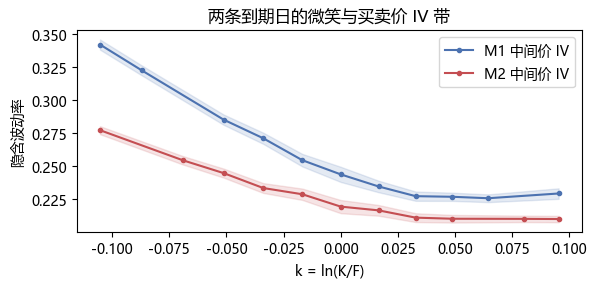

In [3]:

from scipy.optimize import brentq


def implied_vol(price, F, K, T, r, kind):
    if price <= 1e-8:
        return np.nan
    lo = np.exp(-r * T) * (max(F - K, 0.0) if kind == "C" else max(K - F, 0.0))
    hi = np.exp(-r * T) * (F if kind == "C" else K)
    if not (lo + 1e-10 < price < hi - 1e-10):
        return np.nan
    return brentq(lambda v: black76(F, K, T, v, r, kind) - price, 1e-4, 3.0)


otm = clean[((clean.kind == "C") & (clean.K >= F0)) | ((clean.kind == "P") & (clean.K < F0))].copy()
for col in ["bid", "ask", "mid"]:
    otm["iv_" + col] = [implied_vol(p, F0, K, T, r, kind)
                        for p, K, T, kind in zip(otm[col], otm["K"], otm["tau"], otm["kind"])]
otm["k"] = np.log(otm["K"] / F0)
otm["w"] = otm.iv_mid ** 2 * otm["tau"]
print("OTM 合约", len(otm), "条，IV 无解", int(otm.iv_mid.isna().sum()))

atm = otm[np.isclose(otm.k, 0.0)]
print(atm[["expiry", "iv_bid", "iv_mid", "iv_ask"]].round(4).to_string(index=False))
widest = otm.loc[(otm.iv_ask - otm.iv_bid).idxmax()]
print("IV 区间最宽 K=", int(widest["K"]), "宽度", round(float(widest.iv_ask - widest.iv_bid), 4))

w1 = float(atm.loc[atm.expiry == "M1", "w"].iloc[0])
w2 = float(atm.loc[atm.expiry == "M2", "w"].iloc[0])
fw_var = (w2 - w1) / (expiries["M2"] - expiries["M1"])
print("平值总方差 M1/M2", round(w1, 5), round(w2, 5), "区间年化波动", f"{np.sqrt(fw_var):.2%}")

fig, ax = plt.subplots(figsize=(6, 3))
for name, color in zip(expiries, ["#4c72b0", "#c44e52"]):
    sub = otm[otm.expiry == name].sort_values("k")
    ax.plot(sub.k, sub.iv_mid, "o-", markersize=3, color=color, label=f"{name} 中间价 IV")
    ax.fill_between(sub.k, sub.iv_bid, sub.iv_ask, color=color, alpha=0.15)
ax.set_xlabel("k = ln(K/F)")
ax.set_ylabel("隐含波动率")
ax.set_title("两条到期日的微笑与买卖价 IV 带")
ax.legend()
plt.tight_layout()
plt.show()



**读数**：22 条 OTM 合约全部反解成功。平值 M1 的 IV 区间是 23.79%–24.94%（中间价 24.37%），M2 是 21.42%–22.42%（中间价 21.92%）。区间最宽的就是平值行权价，宽度约 1.15 个波动率点。平值总方差 $w_1=0.00488$、$w_2=0.00790$，区间远期年化波动 19.16%——远月总方差更高，但增速低于近月 IV 所暗示的水平，说明远月隐含波动率在下降。

**手算**：$w_1=0.2437^2\times30/365=0.00488$，$w_2=0.2192^2\times60/365=0.00790$，所以

$$\sigma_{1,2}^2=\frac{0.00790-0.00488}{30/365}=0.0367,\qquad \sigma_{1,2}=19.16\%.$$

**常见错误**：

1. 只反解中间价，得到一个“看似精确”的 IV。中间价不是可成交价，要用买卖价给出区间。
2. 深虚值期权硬解。Vega 很小时，价格的一点误差会放大成很大的 IV 误差，宁可标缺失。
3. 直接比较两个期限的 IV。必须换成总方差，否则会把“时间更长”误当成“更贵”。

**停下来想一想**：为什么深虚值期权的隐波最不可靠？

<details><summary>对照你的思路</summary>

隐波反解是“价格误差除以 Vega”。深虚值期权的 Vega 很小，价格对波动率不敏感；买卖价差、最小变动价位、时间戳误差除以小 Vega，会让隐波误差被放大。所以深虚值的 IV 只是“参考值”，不是可交易的点；要保留 bid/ask 区间。

</details>

---

## 3. 无套利：蝶式、垂直、日历

### 3.1 蝶式凸性

同一到期日，看涨价格对行权价必须单调递减且凸：

$$\frac{\partial C}{\partial K}\le0,\qquad \frac{\partial^2C}{\partial K^2}\ge0.$$

若 $C(K)$ 不凸，蝶式组合（买低 $K$、卖两份中 $K$、买高 $K$）的价格为负，等于“别人付钱让你持有非负支付”，就是套利。

### 3.2 用斜率而不是等距二阶差分

清洗后，某些行权价会被删掉，网格不再等距。此时直接用 `np.diff(C, 2)` 会把“缺口”误判成凸性破坏。稳妥做法是算相邻斜率 $s_i=(C_{i+1}-C_i)/(K_{i+1}-K_i)$，检查斜率非递减。垂直价差上下界也落在斜率上：

$$-e^{-rT}\le s_i\le0.$$

### 3.3 日历无套利

总方差随期限不下降：$w(T_2)\ge w(T_1)$，否则“买近卖远”可能存在套利。

### 3.4 代码：注入一条坏报价，看检查器能否抓到

清洗后的链是自洽的，直接查不会出错。为了验证检查器，我们人为把 M1 的 3150 看涨中间价报高 3 元——单条报价仍然“合法”（买价小于卖价、点差正常），清洗抓不到它，只能靠跨行权价检查。



In [4]:

calls = clean[clean.kind == "C"].copy()
probe = calls.index[(calls.expiry == "M1") & (calls.K == 3150)]
calls.loc[probe, "mid"] += 3.0  # 人为把 3150 看涨报高 3 元，点差本身仍合法

for name in expiries:
    sub = calls[calls.expiry == name].sort_values("K")
    slopes = np.diff(sub.mid.values) / np.diff(sub["K"].values)
    kink = np.where(np.diff(slopes) < -1e-9)[0]
    print(name, "斜率递增", bool((np.diff(slopes) >= -1e-9).all()), "拐点个数", int(kink.size))
    if kink.size:
        j = int(kink[0])
        win = sub.iloc[j:j + 3]
        print("  三连窗口 K", win["K"].values.astype(int), "价格", np.round(win.mid.values, 2))

mixed = calls.merge(clean[clean.kind == "P"][["expiry", "K", "mid"]],
                    on=["expiry", "K"], suffixes=("_c", "_p"))
mixed["fwd"] = mixed["K"] + np.exp(r * mixed["tau"].values) * (mixed.mid_c - mixed.mid_p)
dev = (mixed["fwd"] - F0).abs()
worst = mixed.loc[dev.idxmax()]
print("平价反推远期偏离最大", worst.expiry, "K=", int(worst["K"]), "偏离", round(float(dev.max()), 2))

surface = otm[~((otm.expiry == worst.expiry) & (otm.K == worst["K"]))].copy()
calls_ok = calls.drop(index=probe)
for name in expiries:
    sub = calls_ok[calls_ok.expiry == name].sort_values("K")
    slopes = np.diff(sub.mid.values) / np.diff(sub["K"].values)
    print(name, "剔除后斜率仍递增", bool((np.diff(slopes) >= -1e-9).all()))

sub = calls_ok[calls_ok.expiry == "M1"].sort_values("K")
slopes = np.diff(sub.mid.values) / np.diff(sub["K"].values)
print("垂直价差: 价格递减", bool((slopes < 0).all()),
      "斜率不低于 -贴现因子", bool((slopes > -np.exp(-r * sub["tau"].values[0])).all()))

k_grid = np.linspace(-0.08, 0.08, 9)
w_by_expiry = {}
for name in expiries:
    sub = surface[surface.expiry == name].sort_values("k")
    iv_grid = np.interp(k_grid, sub["k"].values, sub.iv_mid.values)
    w_by_expiry[name] = iv_grid ** 2 * expiries[name]
print("同一 k 网格总方差递增", bool((w_by_expiry["M2"] > w_by_expiry["M1"]).all()),
      "最小差", round(float((w_by_expiry["M2"] - w_by_expiry["M1"]).min()), 5))


M1 斜率递增 False 拐点个数 1
  三连窗口 K [3100 3150 3200] 价格 [38.99 29.12 16.73]
M2 斜率递增 True 拐点个数 0
平价反推远期偏离最大 M1 K= 3150 偏离 3.0
M1 剔除后斜率仍递增 True
M2 剔除后斜率仍递增 True
垂直价差: 价格递减 True 斜率不低于 -贴现因子 True
同一 k 网格总方差递增 True 最小差 0.00299



**读数**：M2 干净、斜率递增；M1 因为 3150 被报高，斜率在“3100–3150–3200”这一组出现拐点，三连报价 38.99、29.12、16.73。蝶式检查只能指出“这一段不自洽”，要定位到具体哪一条，用平价：M1 其他行权价反推的远期都是 3000.00，只有 3150 反推出 3003.00，偏离 3.00，正好等于注入的误差。剔除 3150 后，两个到期日斜率都重新递增；垂直价差与日历检查全部通过。

**常见错误**：

1. 用等距二阶差分处理“缺行”的网格，把缺口当成套利。
2. 插值完成后再查套利。正确顺序是：清洗 → 反解 → 无套利检查 → 插值/拟合 → 再查一次。
3. 只用中间价查无套利。真实可交易性要看 bid/ask：买价、卖价分别检查，才能知道套利空间是否真的能吃到。

**停下来想一想**：为什么“蝶式价格为负”等价于套利？

<details><summary>对照你的思路</summary>

蝶式组合在到期时，无论标的价格落在哪里，支付都非负：低 $K$ 的看涨覆盖上涨，高 $K$ 的看涨卖两腿对冲中段。若今天构造这个组合还能收到钱（价格为负），就等于“别人付钱请你持有一个到期不亏的组合”，这是无风险套利。价格凸性正是蝶式价格非负的连续版本。

</details>

---

## 4. SVI：五个参数描述一条微笑

### 4.1 公式与参数

SVI 用总方差 $w(k)$ 描述微笑，$k=\ln(K/F)$：

$$w(k)=a+b\left(\rho(k-m)+\sqrt{(k-m)^2+\sigma^2}\right).$$

**公式拆解**
- **符号**：$k=\ln(K/F)$ 是对数行权价，$w=\sigma^2T$ 是总方差，$a$ 是水平、$b\ge0$ 是斜率尺度、$\rho\in(-1,1)$ 是偏斜、$m$ 是中心、$\sigma>0$ 是平滑度。
- **结构**：$w(k)=a+b(\rho(k-m)+\sqrt{(k-m)^2+\sigma^2})$ 由线性偏斜项和双曲平滑项组成，两翼渐近斜率为 $b(\rho\pm1)$，形成左右不对称的微笑。
- **代入**：本章 M1 参数 $(-0.0011,0.0519,-0.4429,0.0048,0.1122)$ 在平值 $k=0$ 处得 $w\approx0.00483$，折合 IV 约 24.3%，与反解的平值 IV 一致。
- **边界**：$b<0$、$|\rho|\ge1$ 或 $\sigma\le0$ 都不是合法微笑；总方差必须随期限不下降、否则存在日历套利，两翼斜率还要满足 Lee 矩条件。
- **用途**：用五个参数描述整条微笑，做插值、算 25Δ 风险逆转、看曲面随时间的移动；它不含无套利约束，拟合好也要另查蝶式与日历，参数本身不宜过度解读。

- $a$：整体水平；
- $b$：斜率尺度（$b\ge0$）；
- $\rho$：偏斜方向（$|\rho|<1$），负值表示低行权价一侧隐波更高；
- $m$：微笑中心；
- $\sigma$：平滑度（$\sigma>0$）。

### 4.2 拟合

以总方差为目标做最小二乘：

$$\min_{\theta}\sum_i\left(w(k_i;\theta)-w_i\right)^2,$$

并加约束 $b\ge0$、$|\rho|<1$、$\sigma>0$。用 IV 做目标也可以，但加权会被 IV 的大小扭曲，总方差更接近期权价格的尺度。

### 4.3 偏斜与 25Δ 风险逆转

风险逆转（risk reversal）常写成“25Δ 看涨隐波 − 25Δ 看跌隐波”。对 Black–76：

$$\Delta_C=e^{-rT}\Phi(d_1),\qquad \Delta_P=-e^{-rT}\Phi(-d_1).$$

给定 $|\Delta|=0.25$，先解出 $d_1$ 或 $k$，再代入拟合微笑取 IV。风险逆转为负，说明看跌一侧更贵，市场在为下跌尾部付溢价。

### 4.4 代码：拟合 SVI、算偏斜与风险逆转



M1 SVI 拟合 [-0.0011  0.0519 -0.4429  0.0048  0.1122] RMSE 3.2e-05
M2 SVI 拟合 [ 0.0026  0.0482 -0.5358 -0.0021  0.1128] RMSE 7.0e-05


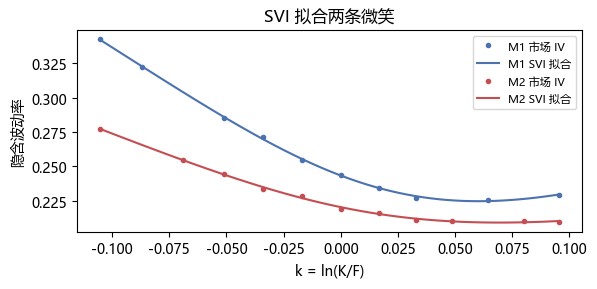

M1 平值 IV 24.33% 25Δ 看涨 IV 22.56% 25Δ 看跌 IV 28.67% 风险逆转(点) -6.11
M2 平值 IV 22.03% 25Δ 看涨 IV 20.92% 25Δ 看跌 IV 25.10% 风险逆转(点) -4.18


In [5]:

from scipy.optimize import brentq, least_squares
from scipy.stats import norm

fits = {}
for name in expiries:
    sub = surface[surface.expiry == name].sort_values("k")
    kk, ww = sub["k"].values, sub["w"].values
    res = least_squares(lambda p: svi_w(kk, *p) - ww,
                        x0=[0.001, 0.04, -0.5, 0.0, 0.1],
                        bounds=([-0.05, 0.0, -0.99, -0.5, 0.001],
                                [0.2, 1.0, 0.99, 0.5, 1.0]))
    fits[name] = res.x
    rmse = np.sqrt(np.mean((svi_w(kk, *res.x) - ww) ** 2))
    print(name, "SVI 拟合", np.round(res.x, 4), "RMSE", f"{rmse:.1e}")

fig, ax = plt.subplots(figsize=(6, 3))
for name, color in zip(expiries, ["#4c72b0", "#c44e52"]):
    sub = surface[surface.expiry == name].sort_values("k")
    kk = np.linspace(sub["k"].min(), sub["k"].max(), 80)
    a, b, rho, m, s = fits[name]
    ax.plot(sub.k, sub.iv_mid, "o", markersize=3, color=color, label=f"{name} 市场 IV")
    ax.plot(kk, np.sqrt(svi_w(kk, a, b, rho, m, s) / expiries[name]), "-",
            color=color, label=f"{name} SVI 拟合")
ax.set_xlabel("k = ln(K/F)")
ax.set_ylabel("隐含波动率")
ax.set_title("SVI 拟合两条微笑")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

for name in expiries:
    T = expiries[name]
    disc = np.exp(-r * T)
    a, b, rho, m, s = fits[name]

    def w_of(k):
        return svi_w(k, a, b, rho, m, s)

    def d1_of(k):
        return (-k + 0.5 * w_of(k)) / np.sqrt(w_of(k))

    target = norm.ppf(0.25 / disc)
    k_call = brentq(lambda k: d1_of(k) - target, -0.5, 0.5)
    k_put = brentq(lambda k: d1_of(k) + target, -0.5, 0.5)
    iv_call = np.sqrt(w_of(k_call) / T)
    iv_put = np.sqrt(w_of(k_put) / T)
    atm_iv = np.sqrt(w_of(0.0) / T)
    print(name, "平值 IV", f"{atm_iv:.2%}", "25Δ 看涨 IV", f"{iv_call:.2%}",
          "25Δ 看跌 IV", f"{iv_put:.2%}", "风险逆转(点)", round(float((iv_call - iv_put) * 100), 2))



**读数**：M1 拟合参数 $(a,b,\rho,m,\sigma)=(-0.0011,0.0519,-0.4429,0.0048,0.1122)$，M2 为 $(0.0026,0.0482,-0.5358,-0.0021,0.1128)$；总方差 RMSE 分别约 $3.2\times10^{-5}$ 与 $7.0\times10^{-5}$，折算成 IV 约 0.1 个波动率点。平值 IV 24.33% 与 22.03%，25Δ 风险逆转分别为 −6.11 与 −4.18 个波动率点：看跌一侧明显更贵，是典型的负偏斜。

**手算**：M1 的贴现因子 $e^{-rT}=0.9984$，25Δ 对应 $\Phi(d_1)=0.25/0.9984=0.2504$，所以 $d_1=\Phi^{-1}(0.2504)\approx-0.674$；代入 $d_1=(-k+\frac12w)/\sqrt w$ 解出 $k$，再取拟合 IV。风险逆转为负，说明 25Δ 看跌的 IV 比 25Δ 看涨高。

**常见错误**：

1. 用 IV 而不是总方差做拟合目标，长到期日权重被放大。
2. 不设参数约束，拟合出 $b<0$ 或 $|\rho|>1$ 的“微笑”。
3. 拟合残差小就认为曲面可交易：还要查蝶式/日历，且要保留 bid/ask 区间。
4. 用同一组 SVI 参数套所有品种/所有日期，忽略结构变化。

**停下来想一想**：风险逆转为负，是否说明“买看跌一定划算”？

<details><summary>对照你的思路</summary>

不是。风险逆转为负只说明市场给看跌的隐波更高，也就是看跌更贵。贵不等于会涨：买方还要付出时间价值，卖方承担尾部风险。是否划算取决于你对未来实际波动、跳空概率、对冲成本和保证金的判断。风险逆转是“价格信号”，不是“收益信号”。

</details>

---

## 5. Greeks 与 Delta 对冲：钱到底从哪来

### 5.1 Black–76 的四个 Greeks

$$C=e^{-rT}\left[F\Phi(d_1)-K\Phi(d_2)\right],\qquad d_1=\frac{\ln(F/K)+\frac12\sigma^2T}{\sigma\sqrt T}.$$

$$\Delta_C=e^{-rT}\Phi(d_1),\qquad
\Gamma=e^{-rT}\frac{\phi(d_1)}{F\sigma\sqrt T},$$

$$\text{Vega}=e^{-rT}F\phi(d_1)\sqrt T,\qquad
\Theta=rC-e^{-rT}\frac{F\phi(d_1)\sigma}{2\sqrt T}.$$

注意单位：Vega 通常报“波动率变化 1 个点（0.01）对应的价格变化”，Theta 报“每年”或“每天”，换算时别漏乘。

### 5.2 离散对冲与 PnL 归因

持有 1 份看涨、用期货做 Delta 对冲，每天调整手数 $h_t=-\Delta_t$。一天内：

$$\Delta V_{\text{净}}\approx
\underbrace{\tfrac12\Gamma(\Delta F)^2}_{\text{Gamma}}+
\underbrace{\text{Vega}\,\Delta\sigma}_{\text{Vega}}+
\underbrace{\Theta\,\Delta t}_{\text{Theta}}+\text{残差}.$$

**公式拆解**
- **符号**：$\Delta V$ 是组合净值变化，$\Gamma$ 是 Gamma、即二阶导，$\Delta F$ 是标的变动，Vega 是波动率敏感度，$\Theta$ 是时间衰减，$\Delta t$ 是持有天数。
- **结构**：四项分别是 $\frac12\Gamma(\Delta F)^2$ 的凸性收益、Vega 乘 $\Delta\sigma$ 的波动率暴露、$\Theta\Delta t$ 的时间损耗和残差，Delta 项已被对冲掉所以不出现。
- **代入**：本章 $\Gamma=0.0019$、$\Delta F=30$ 时 Gamma 项约 0.86 元，Vega 3.42 乘 0.5 个点得 1.71 元，Theta 为 $-1.38$ 元，合计约 +1.19 元。
- **边界**：$\Delta F$ 大时二阶近似失效，隔夜跳空时 $\Delta F$ 与 $\Delta\sigma$ 同时大、残差很大，对冲频率越低残差越大，残差必须单独报告。
- **用途**：解释盈亏来源、评估对冲质量，看组合在靠什么赚钱；它不是精确的会计恒等式，只是事后的泰勒近似，不能拿来预测明天。

残差来自三阶项、Vanna/Volga 交叉项和离散对冲误差。归因不是会计游戏：它告诉你组合在靠什么赚钱、什么风险没被对冲掉。

### 5.3 手算

$F=K=3000$、$T=30/365$、$\sigma=24.29\%$、$r=2\%$ 时，$w=\sigma\sqrt T=0.0699$、$d_1=0.0348$，于是

$$\Delta=0.9984\times\Phi(0.0348)\approx0.513,\qquad
\Gamma=\frac{0.9984\times0.3989}{3000\times0.0699}\approx0.0019,$$

Vega ≈ 3.42 元/波动率点，Theta ≈ −504 元/年 ≈ −1.38 元/天。也就是说，平值看涨每天光时间价值就损耗约 1.4 元；标的每天动 1%，Gamma 大约赚回 $0.5\times0.0019\times30^2\approx0.86$ 元。

### 5.4 代码：逐日对冲与归因



 day        F    iv  opt_pnl  hedge_pnl
   1 3009.132 0.245    4.058     -4.685
   2 3042.211 0.242   16.351    -17.547
   3 3032.519 0.247   -5.612      5.763
   4 3040.266 0.247    3.034     -4.463
   5 3024.998 0.245  -11.057      9.041
   6 3013.388 0.243   -8.329      6.541
   7 3010.875 0.239   -4.240      1.357
   8 3011.754 0.237   -1.792     -0.470
   9 3012.063 0.229   -3.538     -0.166
  10 3022.901 0.227    3.673     -5.846
累计: 期权腿 -7.45 对冲腿 -10.48 净 PnL -17.93
归因: Gamma 1.78 Vega -4.76 Theta -14.92 残差 -0.03


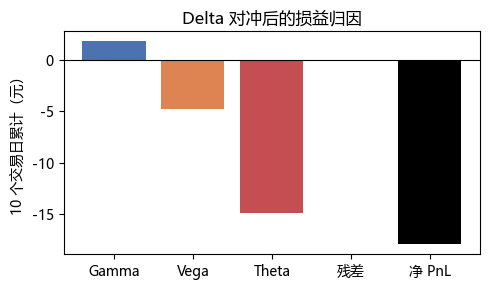

In [6]:

rng = np.random.default_rng(4402)
iv0 = float(np.sqrt(svi_w(0.0, *true_svi["M1"]) / expiries["M1"]))
F_path = [F0]
sig_path = [iv0]
for _ in range(10):
    F_path.append(F_path[-1] * (1 + rng.normal(0.0, 0.008)))
    sig_path.append(float(np.clip(sig_path[-1] + rng.normal(0.0, 0.0025), 0.15, 0.35)))
F_path = np.array(F_path)
sig_path = np.array(sig_path)


def greeks(F, K, T, vol, r):
    w = vol * np.sqrt(T)
    d1 = (np.log(F / K) + 0.5 * w * w) / w
    disc = np.exp(-r * T)
    pdf = np.exp(-0.5 * d1 * d1) / np.sqrt(2 * np.pi)
    delta = disc * ndtr(d1)
    gamma = disc * pdf / (F * w)
    vega = disc * F * pdf * np.sqrt(T) * 0.01
    theta = r * black76(F, K, T, vol, r, "C") - disc * F * pdf * vol / (2 * np.sqrt(T))
    return delta, gamma, vega, theta


K = 3000.0
dt = 1 / 365
rows = []
for t in range(1, 11):
    T_prev, T_now = (30 - (t - 1)) / 365, (30 - t) / 365
    delta, gamma, vega, theta = greeks(F_path[t - 1], K, T_prev, sig_path[t - 1], r)
    opt_pnl = black76(F_path[t], K, T_now, sig_path[t], r) - black76(F_path[t - 1], K, T_prev, sig_path[t - 1], r)
    hedge_pnl = -delta * (F_path[t] - F_path[t - 1])
    gam = 0.5 * gamma * (F_path[t] - F_path[t - 1]) ** 2
    veg = vega * (sig_path[t] - sig_path[t - 1]) * 100
    the = theta * dt
    rows.append([t, F_path[t], sig_path[t], opt_pnl, hedge_pnl, gam, veg, the,
                 opt_pnl + hedge_pnl - gam - veg - the])

book = pd.DataFrame(rows, columns=["day", "F", "iv", "opt_pnl", "hedge_pnl",
                                   "gamma_pnl", "vega_pnl", "theta_pnl", "resid"])
print(book[["day", "F", "iv", "opt_pnl", "hedge_pnl"]].round(3).to_string(index=False))
tot = book[["opt_pnl", "hedge_pnl", "gamma_pnl", "vega_pnl", "theta_pnl", "resid"]].sum()
print("累计: 期权腿", round(float(tot.opt_pnl), 2), "对冲腿", round(float(tot.hedge_pnl), 2),
      "净 PnL", round(float(tot.opt_pnl + tot.hedge_pnl), 2))
print("归因: Gamma", round(float(tot.gamma_pnl), 2), "Vega", round(float(tot.vega_pnl), 2),
      "Theta", round(float(tot.theta_pnl), 2), "残差", round(float(tot.resid), 2))

fig, ax = plt.subplots(figsize=(5, 3))
labels = ["Gamma", "Vega", "Theta", "残差", "净 PnL"]
vals = [float(tot.gamma_pnl), float(tot.vega_pnl), float(tot.theta_pnl),
        float(tot.resid), float(tot.opt_pnl + tot.hedge_pnl)]
ax.bar(labels, vals, color=["#4c72b0", "#dd8452", "#c44e52", "#999999", "black"])
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("10 个交易日累计（元）")
ax.set_title("Delta 对冲后的损益归因")
plt.tight_layout()
plt.show()



**读数**：10 个交易日里标的从 3000 涨到 3022.9（+0.76%），隐波从 24.29% 降到 22.7%。期权腿亏 7.45，对冲腿亏 10.48，净 PnL 为 −17.93。归因：Gamma 赚 1.78，Vega 亏 4.76，Theta 亏 14.92，残差 −0.03。**亏损几乎全部来自时间价值（Theta）**；标的温和上涨带来一点 Gamma 收益，隐波下行让 Vega 亏钱。

**常见错误**：

1. 只对冲 Delta，然后以为“没有方向风险”。Gamma 会让 Delta 变化，标的大动时风险会回来。
2. 用模型价当成交价，忽略买卖价差和手续费。真实对冲成本会把小 PnL 全部吃掉。
3. 归因公式单位混乱：Vega 用“波动率点”还是“波动率绝对值”，Theta 用年还是天，必须统一。
4. 残差大还强行解释。残差大说明样本内价格变化太大，二阶近似失效，应该缩短步长或检查数据。

**停下来想一想**：为什么这组对冲里 Theta 主导，Gamma 只赚了 1.78？

<details><summary>对照你的思路</summary>

因为标的是平值看涨，Gamma 在平值附近最大但金额不大；10 天内标的只涨了 0.76%，每天实现波动远小于隐含波动（24% 年化约 1.2%/天，实际更小），所以 Gamma 赚的钱有限。而 Theta 是“每天固定损耗”，10 天累计约 −15 元，自然成为主导项。若标的大幅波动，Gamma 收益会上升，可能盖过 Theta——这正是“买期权还是卖期权”的核心权衡。

</details>

---

## 6. 从研究到生产：一张检查清单

### 6.1 数据层

- [ ] 期权与期货是同一到期月、同一时间戳吗？
- [ ] 买价 > 0、买价 < 卖价吗？相对点差在阈值内吗？
- [ ] 成交量/持仓是否支持“可成交”？
- [ ] 看跌看涨平价反推的远期是否稳定？

### 6.2 曲面层

- [ ] 只对 OTM 期权反解 IV 吗？
- [ ] 买卖价各一个 IV，保留区间了吗？
- [ ] 蝶式/垂直/日历检查通过吗？
- [ ] SVI 的参数满足约束吗？拟合残差多大？
- [ ] 插值/拟合之后，再查一遍套利了吗？

### 6.3 交易层

- [ ] 对冲频率与交易成本匹配吗？
- [ ] Delta/Gamma/Vega/Theta 的口径统一吗？
- [ ] 极端行情下保证金和流动性够吗？
- [ ] PnL 归因的残差在可接受范围内吗？

---

## 本章小结

### 一张表

| 环节 | 公式/做法 | 用途 |
|---|---|---|
| 清洗 | bid>0、ask>bid、相对点差 | 去掉单条脏报价 |
| 平价 | $C-P=e^{-rT}(F-K)$ | 对账/反推远期 |
| 反解 IV | Black76 求根 | 价格→波动率 |
| 总方差 | $w=\sigma^2T$ | 跨期限比较 |
| 区间方差 | $(w_2-w_1)/(T_2-T_1)$ | 远期波动 |
| 蝶式 | $\partial^2C/\partial K^2\ge0$ | 凸性无套利 |
| 日历 | $w(T_2)\ge w(T_1)$ | 期限无套利 |
| SVI | 5 参数拟合 $w(k)$ | 曲面参数化 |
| 风险逆转 | $IV_{25\Delta C}-IV_{25\Delta P}$ | 偏斜 |
| 归因 | $\frac12\Gamma\Delta F^2+\text{Vega}\Delta\sigma+\Theta\Delta t$ | 对冲账 |

### 八句话

1. 中间价是研究标记，买价/卖价才是可成交边界。
2. 先清洗、再反解、再查套利、最后拟合，顺序不能反。
3. 深虚值 Vega 小，隐波误差被放大。
4. 比较期限先转总方差，不要直接比 IV。
5. 负蝶式等于套利；检查要用斜率，别用等距二阶差分。
6. SVI 拟合好不等于无套利，也不等于可交易。
7. 风险逆转为负是价格信号，不是收益信号。
8. Delta 对冲只消一阶方向风险，Gamma/Vega/Theta 还在。

---

## 本章习题

**1.** 一张链里买价为 0、买价等于卖价、相对点差 30%、成交量为 0 各对应哪条清洗规则？分别可能是什么原因？

**2.** $F=3000$、$K=3000$、$T=30/365$、$r=2\%$，平值 IV 从 24% 升到 26%。总方差从多少变到多少？

**3.** 近月总方差 $w_1=0.004$、$T_1=0.25$；远月 $w_2=0.010$、$T_2=0.5$。求区间年化方差与年化波动。

**4.** 用看涨价差解释：为什么 $C(K)$ 必须单调递减且凸？

**5.** 某行权价上，看涨中间价反推的远期比其他行权价高 3 元。可能是什么问题？应该怎么处理？

**6.** SVI 中 $\rho=-0.55$ 大致说明什么？如果拟合出 $\rho=-1.2$，说明什么？

**7.** $F=K=3000$、$T=30/365$、$\sigma=24.29\%$、$r=2\%$。写出 Delta、Gamma、Vega、Theta 的近似值（可用 $d_1\approx0.035$、$\phi(0.035)\approx0.399$、$\Phi(0.035)\approx0.514$）。

**8.** 买入 1 份平值看涨并做 Delta 对冲，10 天后标的几乎没动、隐波下降 2 个点。PnL 主要来自哪几项？符号分别是什么？

<details><summary>参考答案</summary>

**1.** 买价为 0 → 无人买/流动性枯竭；买价等于卖价 → 交叉或锁死报价（应为 ask>bid）；相对点差 30% → 点差过宽，流动性差；成交量为 0 → 报价不新鲜。前两条直接剔除，后两条视研究口径降权或剔除。

**2.** $w_1=0.24^2\times30/365=0.00473$；$w_2=0.26^2\times30/365=0.00556$。总方差增加约 0.00083。

**3.** 区间方差 $(0.010-0.004)/(0.5-0.25)=0.024$，年化波动 $\sqrt{0.024}\approx15.5\%$。

**4.** 若 $K_1<K_2$ 但 $C(K_1)\le C(K_2)$，买低行权价、卖高行权价可锁定非负支付还倒收钱；若二阶差分小于 0，蝶式组合价格为负。两者都是无风险套利，因此价格必须递减且凸。

**5.** 可能是该行权价报价陈旧、买卖价错位、或者看涨看跌时间戳不一致。先用平价把该行与同执行价的看跌对照，找出偏离的一条；剔除或按相邻插值修复后重查凸性。

**6.** $\rho=-0.55$ 说明低行权价（看跌）一侧隐波更高，是负偏斜；$\rho=-1.2$ 超出 $|\rho|<1$ 的约束，说明拟合失败或数据严重违反 SVI 假设，不能直接用。

**7.** $\Delta\approx0.513$，$\Gamma\approx0.0019$，Vega≈3.42 元/波动率点，Theta≈−504 元/年（约 −1.38 元/天）。

**8.** 主要来自 Theta（负，时间价值损耗）和 Vega（负，隐波下降）。Gamma 接近 0（标的没动），Delta 项被对冲掉；净 PnL 为负。

</details>

---

## 参考资料

- Hull, J. C. *Options, Futures, and Other Derivatives*（期权链、Greeks、对冲）。
- Black, F. (1976). The Pricing of Commodity Contracts（Black–76）。
- Gatheral, J. *The Volatility Surface*（SVI 与无套利）。
- Gatheral, J. & Jacquier, A. (2014). Arbitrage-free SVI volatility surfaces.
- CBOE, *VIX White Paper*（总方差与期限结构）。
- 第24、25、26、27章（期权定价、Greeks、曲面、动态对冲）。
